Path data, arcs, markers, baked transforms and registered composite shapes.

Run it as ``python paths_and_markers.py`` or open ``paths_and_markers.ipynb`` to see each step.

In [1]:
import os
import tempfile
from pathlib import Path

import svgwriter as svg
from svgwriter import builder

`PathBuilder` writes path data with chained commands. Relative quadratic curves make a wave,
and `builder.arrow_marker` gives it an arrow head at its end.

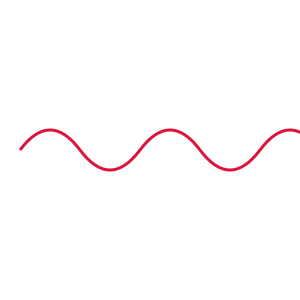

In [2]:
SIZE = 300
doc = svg.Document(SIZE, SIZE)
head = builder.arrow_marker("crimson", 6)

wave = svg.PathBuilder().move_to(20, 150)
for _ in range(4):
    wave.quad_to(30, -40, 60, 0, relative=True).smooth_quad_to(60, 0, relative=True)
doc.path(wave, fill="none", stroke="crimson", stroke_width=3, marker_end=head)
doc

Arcs: a pie slice from a line and an elliptical `arc_to`. `clone().rotate(...)` bakes a rotation
into a copy, giving the opposite slice.

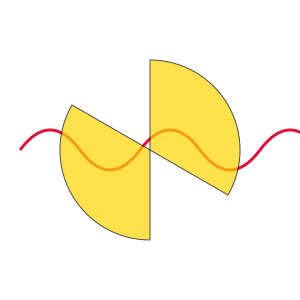

In [3]:
pie = svg.PathBuilder().move_to(150, 150).line_to(150, 60).arc_to(90, 90, 0, False, True, 228, 195).close()
slice_ = doc.path(pie, fill="gold", stroke="black", opacity=0.7)
doc += slice_.clone().rotate(180, about=(150, 150))
doc

`svgwriter.builder` has registered composite shapes (star, gear, arrow, dashed line) that return
ordinary shapes, here added together to one group.

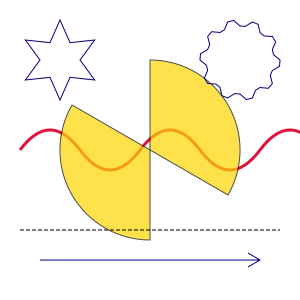

In [4]:
with doc.group(stroke="navy", fill="none") as outlines:
    outlines += [
        builder.star(60, 60, 40, points=6),
        builder.gear(240, 60, 40, teeth=10),
        builder.arrow(40, 260, 260, 260, head=14),
        builder.dashed_line(20, 230, 280, 230),
    ]
doc

Save a readable file and a compact one (shorter path data, fewer digits).
Set `SVGWRITER_EXAMPLES_OUT` to choose the folder.

In [5]:
out = Path(os.environ.get("SVGWRITER_EXAMPLES_OUT") or tempfile.mkdtemp(prefix="svgwriter-"))
out.mkdir(parents=True, exist_ok=True)
doc.save(out / "paths_pretty.svg")
doc.save(out / "paths_compact.svg", pretty=False, compact_paths=True, precision=2)
for name in ("paths_pretty.svg", "paths_compact.svg"):
    print("saved", name)

saved paths_pretty.svg
saved paths_compact.svg
